# Exoplanet Detection

## Scientific Objective

Determine whether summary statistics extracted from Kepler light curves can distinguish confirmed exoplanets from false positives.

## Research Questions

1. Which summary features are most informative?
2. How well can logistic regression classify candidates?
3. Do neural networks improve classification performance?
4. Can a CNN learn additional information from the
   phase-folded light curves?

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42

print("Python:", sys.version.split()[0])
print("Pandas version:", pd.__version__)

Python: 3.10.21
Pandas version: 2.3.3


In [2]:
DATA_PATH = Path("data/kepler_candidates.csv")

assert DATA_PATH.exists(), f"File not found: {DATA_PATH}"

df_raw = pd.read_csv(DATA_PATH)

print("Dataset shape:", df_raw.shape)

display(df_raw.head())

Dataset shape: (1194, 9)


,period,depth,snr,evenodd_ratio,folded_std,folded_min,folded_ptp,label,kepid
0,16.945922,0.000663,43.070756,0.905964,0.000089,0.999228,0.000908,1,12470844
1,3.340560,0.000947,32.228469,1.049964,0.000180,0.998850,0.001369,1,4139816
2,20.505063,0.001751,37.478537,1.004201,0.000182,0.998129,0.002140,1,4049131
3,7.496200,0.000344,8.078393,0.964368,0.000077,0.999561,0.000556,0,11913073
4,0.600000,0.000000,NaN,100.000000,0.000029,0.999933,0.000156,0,6756669


In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1194 entries, 0 to 1193
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   period         1194 non-null   float64
 1   depth          1194 non-null   float64
 2   snr            1171 non-null   float64
 3   evenodd_ratio  1194 non-null   float64
 4   folded_std     1192 non-null   float64
 5   folded_min     1192 non-null   float64
 6   folded_ptp     1192 non-null   float64
 7   label          1194 non-null   int64  
 8   kepid          1194 non-null   int64  
dtypes: float64(7), int64(2)
memory usage: 84.1 KB


In [4]:
# display(df_raw.describe())
# Raw-data diagnostics without potentially overflowing variance calculations

raw_features = df_raw.drop(columns=["label", "kepid"])

display(
    raw_features.agg(["count", "min", "median", "max"]).T
)

,count,min,median,max
period,1194.0,6.000000e-01,9.474430,2.998530e+01
depth,1194.0,-1.724372e+95,0.000234,1.234222e+305
snr,1171.0,2.166368e+00,21.369194,7.467999e+01
evenodd_ratio,1194.0,1.477321e-03,1.021024,1.818261e+03
folded_std,1192.0,1.696730e-06,0.000050,1.635385e-01
folded_min,1192.0,3.625800e-01,0.999778,9.999963e-01
folded_ptp,1192.0,7.640457e-06,0.000356,7.159549e-01


### 7 predictors:
| Category | Features |
| :--- | :--- |
| **Transit timing** | period |
| **Signal characteristics** | depth, snr |
| **Transit consistency** | evenodd_ratio |
| **Folded light-curve morphology** | folded_std, folded_min, folded_ptp |

In [5]:
# Missing values
missing = df_raw.isna().sum()

display(missing[missing > 0])

# Duplicate stellar identifiers
n_duplicates = df_raw.duplicated(subset="kepid").sum()
print("Repeated kepid values:", n_duplicates)

# Class distribution
display(df_raw["label"].value_counts(dropna=False))

snr           23
folded_std     2
folded_min     2
folded_ptp     2
dtype: int64

Repeated kepid values: 0


label
0    879
1    315
Name: count, dtype: int64

## Features and labels

In [6]:
# Preprocess the raw dataframe by removing missing values and duplicate entries based on 'kepid'
df = df_raw.dropna().copy()
df = df.drop_duplicates(subset="kepid", keep="first")

X = df.drop(columns=["label", "kepid"])
y = df["label"]

print("Original examples:", len(df_raw))
print("Retained examples:", len(df))
print("Feature matrix:", X.shape)
print("Target vector:", y.shape)

Original examples: 1194
Retained examples: 1171
Feature matrix: (1171, 7)
Target vector: (1171,)


In [7]:
# Verify the cleaned feature matrix

assert np.isfinite(X.to_numpy()).all()
assert df["kepid"].is_unique

print("Removed records:", len(df_raw) - len(df))
print("Retained records:", len(df))
print("Class counts:")
display(y.value_counts().sort_index())

display(X.describe().T)

Removed records: 23
Retained records: 1171
Class counts:


label
0    860
1    311
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max
period,1171.0,11.995221,9.254824,0.608987,3.354595,9.750802,20.489494,29.985298
depth,1171.0,0.010388,0.039999,0.000002,0.000090,0.000237,0.000883,0.453446
snr,1171.0,25.466031,18.876451,2.166368,7.514070,21.369194,39.717317,74.679987
evenodd_ratio,1171.0,20.084873,65.100836,0.001477,0.934045,1.017576,1.487164,1818.260960
folded_std,1171.0,0.003200,0.013222,0.000002,0.000025,0.000052,0.000195,0.163538
folded_min,1171.0,0.985789,0.054824,0.362580,0.999092,0.999773,0.999912,0.999996
folded_ptp,1171.0,0.016189,0.062498,0.000008,0.000165,0.000363,0.001278,0.715955


### Data-quality assessment

The original dataset contains 1,194 observations. After
removing records with missing values, 1,171 observations
remain.

No repeated `kepid` identifiers are present in the
summary dataset.

The raw dataset also contains extreme, nonphysical
numerical values in `depth`. These cause overflow when
calculating raw descriptive statistics. All seven
features are finite after complete-case filtering.

The retained dataset is imbalanced: 860 negative
examples and 311 positive examples.

The supplied class labels are used as the course
benchmark. Their catalog provenance is examined more
carefully in Notebook 2.

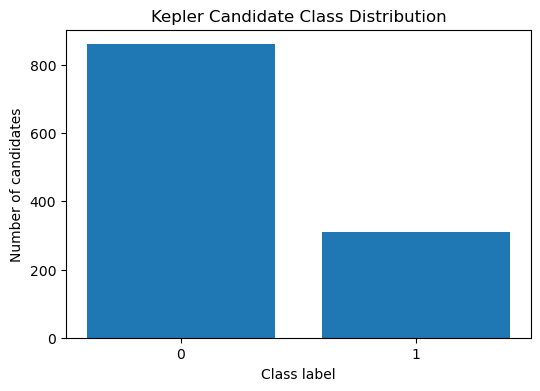

In [8]:
# Visualize the distribution of class labels in the retained dataset
counts = y.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(counts.index.astype(str), counts.values)

ax.set_xlabel("Class label")
ax.set_ylabel("Number of candidates")
ax.set_title("Kepler Candidate Class Distribution")

plt.show()

| Preprocessing step | What we did | Result |
|---|---|---|
| Load data | Read candidate summary dataset | 1,194 records |
| Remove incomplete records | Drop rows containing any missing values | 23 removed |
| Check duplicates | Check identifier (`kepid`) | 0 duplicates removed |
| Select predictors | Retain seven numerical features | 7 input features |
| Separate target and identifier | Target: `label` ; exclude `label` and `kepid` | No identifiers used as inputs |
| Final dataset | Retain complete, unique observations | **1,171 records** |
| Final class distribution | Count the retained observations by label | **860 class 0; 311 class 1** |

# Mathematical model

Logistic regression models the probability of a binary outcome:
$$
P(y=1\mid\mathbf{x})=\sigma(z)
=\frac{1}{1+e^{-z}}
$$

where
$$
z=\beta_0+\sum_{j=1}^{7}\beta_j x_j.
$$

The model learns the coefficients $\beta_j$ by minimizing a classification loss, generally binary cross-entropy, with optional regularization.

Our first model will use L2 regularization, with the default threshold of 0.5 for assigning class labels.

In [9]:
# Split the dataset into training and testing sets
from sklearn.model_selection import train_test_split

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.20,
    stratify=y_dev,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (748, 7)
Validation: (188, 7)
Testing: (235, 7)


In [10]:
# Establish a trivial baseline
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")

dummy.fit(X_train, y_train)

,strategy,'most_frequent'
,random_state,None
,constant,None


## Logistic regression

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

logreg.fit(X_train, y_train)

,steps,"[('scaler', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


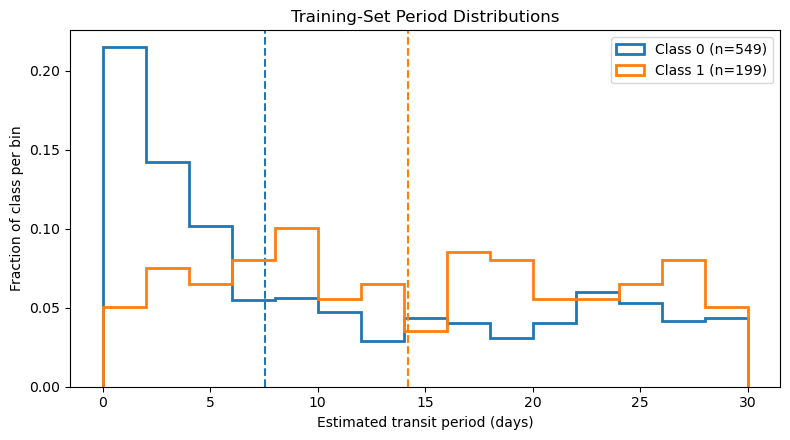

,count,median,mean
label,,,
0,549,7.535411,10.798098
1,199,14.199735,14.718383


In [12]:
from pathlib import Path

FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)

# Use training data only
eda_train = X_train.copy()
eda_train["label"] = y_train.to_numpy()

fig, ax = plt.subplots(figsize=(8, 4.5))

colors = {0: "tab:blue", 1: "tab:orange"}
bins = np.linspace(0, 30, 16)

for cls in [0, 1]:
    periods = eda_train.loc[
        eda_train["label"] == cls, "period"
    ]

    ax.hist(
        periods,
        bins=bins,
        weights=np.ones(len(periods)) / len(periods),
        histtype="step",
        linewidth=2,
        color=colors[cls],
        label=f"Class {cls} (n={len(periods)})"
    )

    ax.axvline(
        periods.median(),
        color=colors[cls],
        linestyle="--",
        linewidth=1.5
    )

ax.set_xlabel("Estimated transit period (days)")
ax.set_ylabel("Fraction of class per bin")
ax.set_title("Training-Set Period Distributions")
ax.legend()

plt.tight_layout()
fig.savefig(
    FIGURE_DIR / "eda_period_by_class.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

display(
    eda_train.groupby("label")["period"]
    .agg(["count", "median", "mean"])
)

### Interpretation: Transit period

The positive and negative classes show different
period distributions in the training sample.

The median estimated period is approximately 14.20
days for class 1 and 7.54 days for class 0.

However, the distributions overlap substantially.
Therefore, period alone is unlikely to provide reliable
classification.

This difference should not be interpreted as a causal
relationship between orbital period and planetary
authenticity. Selection effects and the construction
of the candidate dataset may influence the observed
distributions.

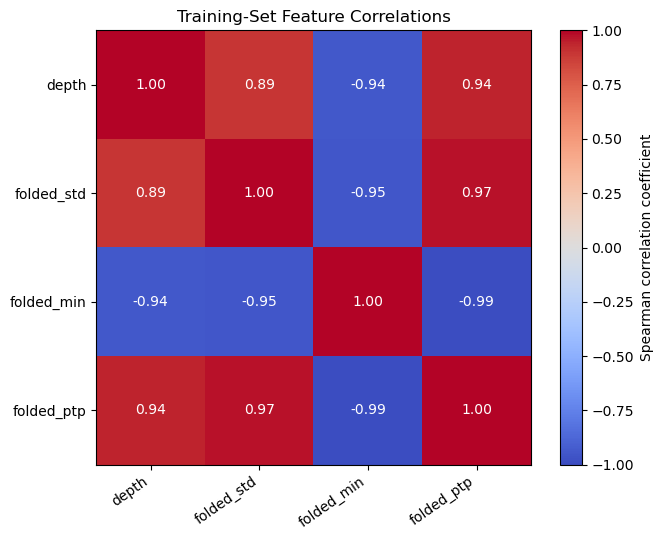

In [13]:
features = [
    "depth",
    "folded_std",
    "folded_min",
    "folded_ptp"
]

corr = X_train[features].corr(method="spearman")

fig, ax = plt.subplots(figsize=(7, 5.5))

im = ax.imshow(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(features)))
ax.set_yticks(range(len(features)))

ax.set_xticklabels(features, rotation=35, ha="right")
ax.set_yticklabels(features)

for i in range(len(features)):
    for j in range(len(features)):
        value = corr.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if abs(value) > 0.65 else "black"
        )

fig.colorbar(
    im,
    ax=ax,
    label="Spearman correlation coefficient"
)

ax.set_title("Training-Set Feature Correlations")

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "eda_feature_correlations.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Interpretation: Feature correlations

Several flux-derived features are strongly correlated.

In particular, transit depth, minimum folded flux,
and peak-to-peak flux variation encode overlapping
information about the amplitude and structure of
the processed transit signal.

Strong correlation does not mean a feature is useless.
However, the predictors are not statistically
independent, and their contributions to a fitted
classifier may be difficult to interpret individually.

This motivates regularization in logistic regression
and comparison with nonlinear models.

The correlation analysis is descriptive and does not
establish which features are causally important for
planet classification.

In [14]:
# Evaluate the performance of different models on the validation set using various classification metrics
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

def evaluate_model(name, model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    probabilities = model.predict_proba(X_eval)[:, 1]

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_eval, predictions
        ),
        "Precision": precision_score(
            y_eval, predictions, zero_division=0
        ),
        "Recall": recall_score(y_eval, predictions),
        "F1": f1_score(
            y_eval, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_eval, probabilities
        ),
        "Average Precision": average_precision_score(
            y_eval, probabilities
        )
    }

results = pd.DataFrame([
    evaluate_model("Dummy", dummy, X_val, y_val),
    evaluate_model("Logistic Regression", logreg, X_val, y_val)
])

display(results.set_index("Model").round(3))

,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
Model,,,,,,,
Dummy,0.734,0.500,0.000,0.0,0.000,0.500,0.266
Logistic Regression,0.739,0.536,0.556,0.1,0.169,0.732,0.435


Logistic regression improves all three metrics, although recall remains low.

| Metric | Dummy classifier | Logistic regression |
|---|---:|---:|
| ROC-AUC | 0.500 | **0.732** |
| Average precision | 0.266 | **0.435** |
| Recall at threshold 0.5 | 0% | **10%** |
| Accuracy | 73.4% | 73.9% |

Accuracy improves only slightly because class 0 dominates the dataset. The ROC-AUC and average-precision gains show better ranking of class-1 candidates, but detecting only 10% of them is still poor.

## ROC and precision–recall curves

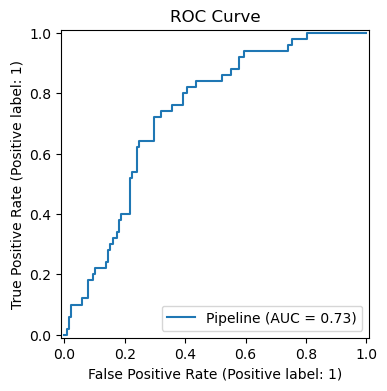

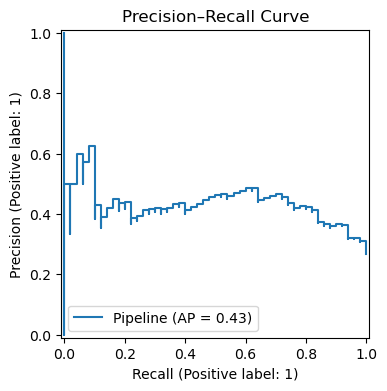

In [15]:
from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# RocCurveDisplay.from_estimator(
#     logreg, X_val, y_val, ax=axes[0]
# )

# PrecisionRecallDisplay.from_estimator(
#     logreg, X_val, y_val, ax=axes[1]
# )

# axes[0].set_title("ROC Curve")
# axes[1].set_title("Precision–Recall Curve")

# plt.tight_layout()
# plt.show()

# Separate the ROC and Precision–Recall curves for better visualization
fig, ax = plt.subplots(figsize=(6, 4))
RocCurveDisplay.from_estimator(logreg, X_val, y_val, ax=ax)
ax.set_title("ROC Curve")
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
PrecisionRecallDisplay.from_estimator(logreg, X_val, y_val, ax=ax)
ax.set_title("Precision–Recall Curve")
plt.show()

ROC-AUC measures ranking across thresholds; recall measures detection at one threshold. Class-1 candidates can receive higher scores than class-0 candidates while most still score below 0.5. This produces a reasonable ROC-AUC alongside poor recall at 0.5. Lowering the threshold can improve recall, at the cost of more false positives; select that threshold using validation data before evaluating the test set.

### Experiment A — Class weighting at a fixed cutoff

We compare the unweighted fit with a second fit that uses `class_weight="balanced"`. The weighted fit gives more weight to the rarer positive class using the training class frequencies. Both fits are trained on the same candidates and evaluated at a cutoff of **0.5** on the same 188 validation candidates.

The two matrices use raw counts and share a color scale with the matrices in Experiment B.

In [16]:
# Train the weighted classifier
weighted_logreg = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

weighted_logreg.fit(X_train, y_train)

print("Weighted logistic regression trained.")

Weighted logistic regression trained.


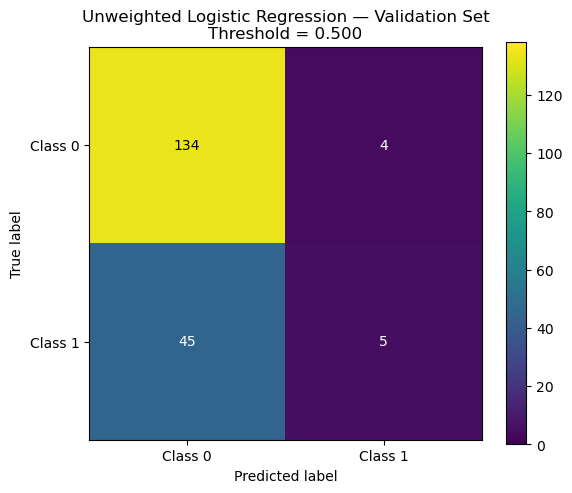

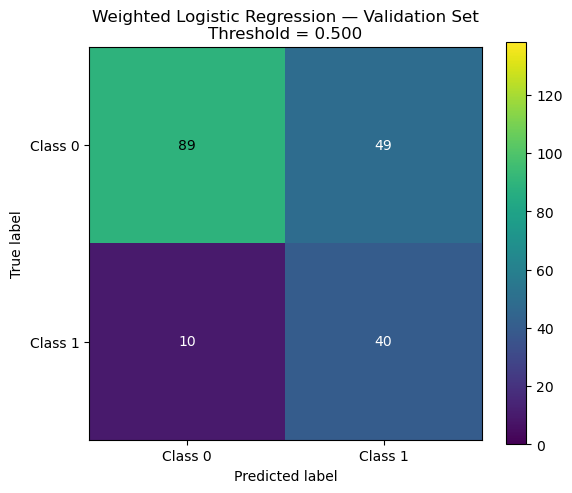

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

def plot_validation_cm(name, probabilities, threshold, filename):
    fig, ax = plt.subplots(figsize=(6, 5))
    max_count = int(y_val.value_counts().max())

    disp = ConfusionMatrixDisplay.from_predictions(
        y_val,
        probabilities >= threshold,
        labels=[0, 1],
        display_labels=["Class 0", "Class 1"],
        ax=ax,
        cmap="viridis",
        values_format="d",
        im_kw={"vmin": 0, "vmax": max_count},
    )

    # Keep the count labels readable on the shared scale.
    for label, count in zip(disp.text_.flat, disp.confusion_matrix.flat):
        label.set_color("white" if count < max_count / 2 else "black")

    ax.set_title(f"{name} — Validation Set\nThreshold = {threshold:.3f}")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, dpi=250, bbox_inches="tight")
    plt.show()



fixed_threshold = 0.5
logistic_validation_probs = {
    "Logistic Regression": logreg.predict_proba(X_val)[:, 1],
    "Weighted Logistic": weighted_logreg.predict_proba(X_val)[:, 1],
}

plot_validation_cm(
    "Unweighted Logistic Regression", logistic_validation_probs["Logistic Regression"],
    fixed_threshold, "logreg_validation_confusion_matrix.png",
)
plot_validation_cm(
    "Weighted Logistic Regression", logistic_validation_probs["Weighted Logistic"],
    fixed_threshold, "weighted_logreg_validation_confusion_matrix.png",
)

At 0.5 the unweighted fit misses **45 of 50** positives. With weighting and the same cutoff, misses fall to **10 of 50**. Recall rises from **10% to 80%**, while false positives rise from **4 to 49**.

### Experiment B — Select each cutoff using validation F2

We reuse both fitted models from Experiment A. For each model, we try cutoffs from 0.05 through 0.95 in steps of 0.005 and select the one with the highest validation F2. With precision $P$ and recall $R$, $F_2=5PR/(4P+R)$ gives recall more weight for this screening task.

The table compares all four settings. Both tuned rows measure performance on the same validation candidates used to pick their cutoffs.

Threshold  ROC-AUC     AP  Precision  \
Experiment        Model                                                       
A · Common cutoff Logistic Regression      0.500    0.732  0.435      0.556   
                  Weighted Logistic        0.500    0.736  0.431      0.449   
B · Validation F2 Logistic Regression      0.215    0.732  0.435      0.362   
                  Weighted Logistic        0.435    0.736  0.431      0.373   

                                       Recall     F2  FP  FN  
Experiment        Model                                       
A · Common cutoff Logistic Regression    0.10  0.120   4  45  
                  Weighted Logistic      0.80  0.692  49  10  
B · Validation F2 Logistic Regression    0.94  0.712  83   3  
                  Weighted Logistic      0.94  0.721  79   3

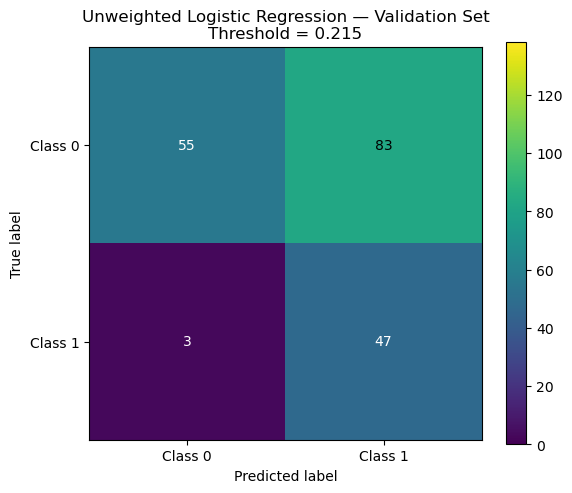

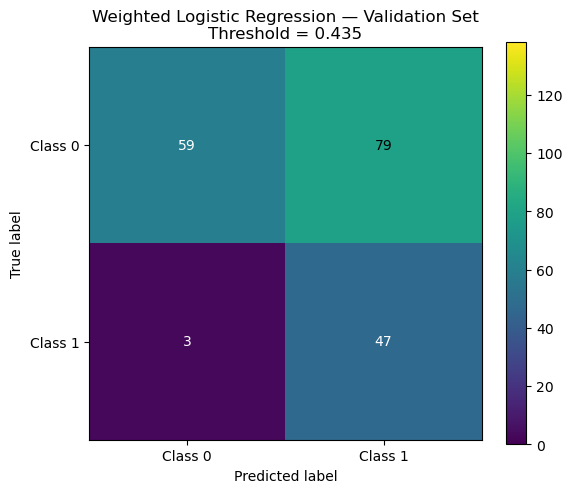

In [18]:
from sklearn.metrics import confusion_matrix, fbeta_score


def choose_threshold(y_true, probabilities):
    thresholds = np.linspace(0.05, 0.95, 181)
    scores = [
        fbeta_score(y_true, probabilities >= threshold, beta=2, zero_division=0)
        for threshold in thresholds
    ]
    return float(thresholds[np.argmax(scores)])


def summarize_model(name, y_true, probabilities, threshold=None):
    if threshold is None:
        threshold = choose_threshold(y_true, probabilities)

    predictions = probabilities >= threshold
    _, fp, fn, _ = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        "Model": name,
        "Threshold": threshold,
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "AP": average_precision_score(y_true, probabilities),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F2": fbeta_score(y_true, predictions, beta=2, zero_division=0),
        "FP": fp,
        "FN": fn,
    }


fixed_results = pd.DataFrame([
    summarize_model(name, y_val, probabilities, threshold=fixed_threshold)
    for name, probabilities in logistic_validation_probs.items()
]).set_index("Model")

tuned_results = pd.DataFrame([
    summarize_model(name, y_val, probabilities)
    for name, probabilities in logistic_validation_probs.items()
]).set_index("Model")

comparison = pd.concat({
    "A · Common cutoff": fixed_results,
    "B · Validation F2": tuned_results,
}, names=["Experiment"])
display(comparison.round(3))

plot_validation_cm(
    "Unweighted Logistic Regression", logistic_validation_probs["Logistic Regression"],
    tuned_results.loc["Logistic Regression", "Threshold"],
    "logreg_validation_f2_confusion_matrix.png",
)
plot_validation_cm(
    "Weighted Logistic Regression", logistic_validation_probs["Weighted Logistic"],
    tuned_results.loc["Weighted Logistic", "Threshold"],
    "weighted_logreg_validation_f2_confusion_matrix.png",
)

# The MLP section adds its validation scores to this dictionary.
validation_probs = logistic_validation_probs.copy()

Validation F2 selects **0.215 for the unweighted fit** and **0.435 for the weighted fit**. Both catch **47 of 50** positives. At that recall, the weighted fit produces **79** false positives compared with **83** for the unweighted fit.

ROC-AUC and average precision use the underlying scores, so each fit has the same ranking metrics in A and B. Those metrics are close across the two fits. The next question is whether an MLP using the same seven features can improve precision at high recall.

## Multilayer perceptron

Can nonlinear combinations of the same seven features improve screening at high recall? The MLP and the logistic models use the same 748 training candidates and 188 validation candidates. The MLP scaler learns the feature means and standard deviations from the training set and applies them to validation.

The architecture is **7 → 16 → 8 → 1**, with ReLU in both hidden layers and 20% dropout after the first. The single output is a class-1 logit. We train with weighted binary cross-entropy and restore the checkpoint selected by validation loss. We then choose the cutoff by maximizing validation F2, using the same rule as Experiment B.

### Fit the model

In [19]:
from script.train_mlp import fit_mlp, mlp_probabilities

In [20]:
mlp, scaler_mlp, history, best_loss = fit_mlp(X_train, y_train, X_val, y_val)
print("Best validation loss:", best_loss)

Best validation loss: 0.767869770526886


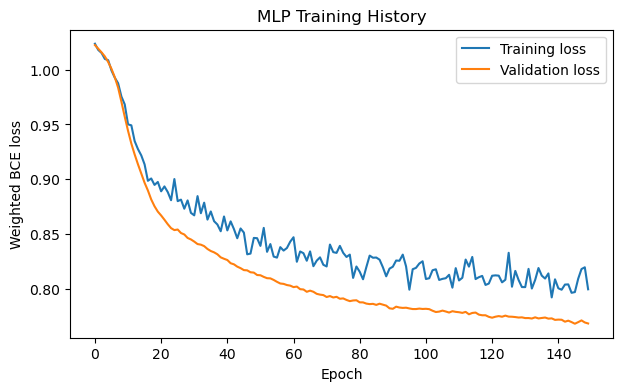

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(history["train"], label="Training loss")
ax.plot(history["val"], label="Validation loss")

ax.set_xlabel("Epoch")
ax.set_ylabel("Weighted BCE loss")
ax.set_title("MLP Training History")
ax.legend()

plt.show()

In [22]:
validation_probs["MLP"] = mlp_probabilities(mlp, scaler_mlp, X_val)

validation_results = pd.DataFrame([
    summarize_model(name, y_val, probabilities)
    for name, probabilities in validation_probs.items()
])

display(
    validation_results
    .sort_values("F2", ascending=False)
    .round(3)
)

,Model,Threshold,ROC-AUC,AP,Precision,Recall,F2,FP,FN
2,MLP,0.340,0.806,0.536,0.403,1.00,0.772,74,0
1,Weighted Logistic,0.435,0.736,0.431,0.373,0.94,0.721,79,3
0,Logistic Regression,0.215,0.732,0.435,0.362,0.94,0.712,83,3


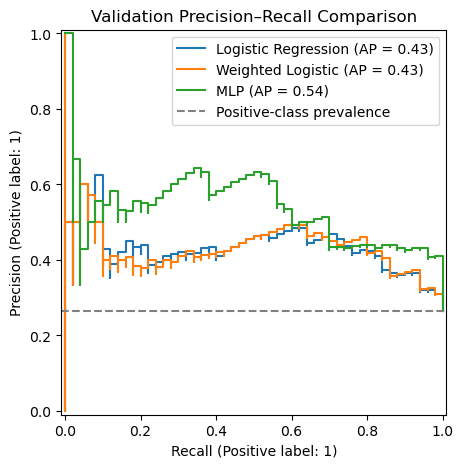

In [23]:
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(7, 5))

for name, probabilities in validation_probs.items():
    PrecisionRecallDisplay.from_predictions(
        y_val,
        probabilities,
        name=name,
        ax=ax
    )

ax.axhline(
    y_val.mean(),
    linestyle="--",
    color="gray",
    label="Positive-class prevalence"
)

ax.set_title("Validation Precision–Recall Comparison")
ax.legend()

plt.show()

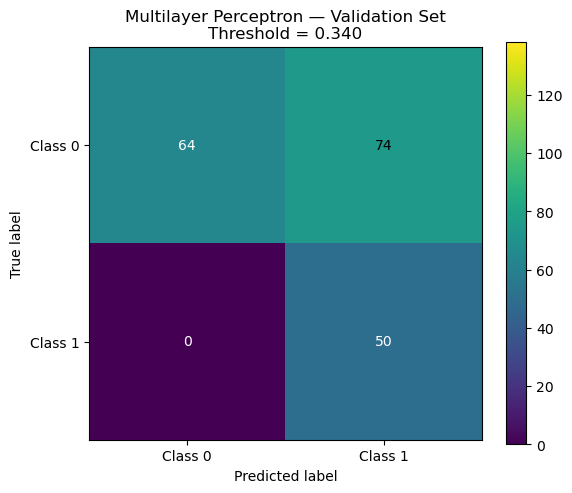

In [24]:
mlp_threshold = validation_results.loc[
    validation_results["Model"] == "MLP", "Threshold"
].item()

plot_validation_cm(
    "Multilayer Perceptron", validation_probs["MLP"], mlp_threshold,
    "mlp_validation_f2_confusion_matrix.png",
)

## Conclusions and Connection to Notebook 2

At its validation F2 cutoff of **0.340**, the MLP finds **50 of 50 positives** and produces **74 false positives**. In Experiment B, weighted logistic regression finds **47 of 50 positives** and produces **79 false positives**. The MLP's precision is **40.3%**, so most of the candidates it flags are false positives. The MLP checkpoint and cutoff were both selected on this validation set.

This notebook established three feature-based
classification approaches for the Kepler
exoplanet dataset:

1. Majority-class and logistic-regression baselines.
2. Class weighting at a common cutoff and cutoff selection using validation F2.
3. A regularized multilayer perceptron.

The main findings are:

- Class imbalance makes accuracy an insufficient
  measure of classification performance.
- Logistic regression learns some discriminating
  information, but its default threshold produces
  poor positive-class recall.
- Threshold selection can improve recall, although
  it increases false positives.
- The MLP shows stronger validation discrimination
  than the linear models.
- High recall does not imply reliable positive
  identification.

### Limitations

This analysis uses a relatively small dataset,
a single data partition, and supplied binary labels.

Feature correlations and possible preprocessing
artifacts complicate interpretation.

The neural network was evaluated using a single
training seed. Its stability across independent
training runs has not been established.

### Next question

Can the shape of a phase-folded light curve improve on the feature-based MLP? Notebook 2 refits the MLP on the eligible training candidates and compares it with a compact 1D CNN on the same held-out candidates. This gives both models the same evaluation sample.